# Bank Marketing — Customer Term-Deposit Subscription Classification

**BITS Pilani | M.Tech (DSE) | Machine Learning Assignment 2**

This notebook follows an end-to-end workflow: dataset inspection, preprocessing, exploratory analysis, model tuning, evaluation, fit diagnostics and artifact export.

**Prediction task:** predict whether a customer subscribes to a term deposit (`y = yes`) or does not (`y = no`).

> This is a binary classification problem. The positive class is `yes`. The feature `duration` is deliberately excluded because it records call duration and is not available before a call; using it would create post-event information leakage.


## 1. Setup and reproducibility

In [93]:
from pathlib import Path
import io
import zipfile
import urllib.request
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix, classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

RANDOM_STATE = 42
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
MODEL_DIR = ROOT / "model"
REPORT_DIR = ROOT / "reports"
for folder in (DATA_DIR, MODEL_DIR, REPORT_DIR):
    folder.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)


In [119]:
import sys
import numpy
import sklearn
import joblib

print("Python:", sys.version)
print("Python path:", sys.executable)
print("NumPy:", numpy.__version__)
print("Sklearn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

Python: 3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]
Python path: c:\Users\Ashwani\anaconda3\envs\bank311\python.exe
NumPy: 2.4.6
Sklearn: 1.9.1
Joblib: 1.6.0


In [94]:
import os

print("current working directory:")
print(os.getcwd())

current working directory:
d:\Bank_Marketing_Classification_Assignment


## 2. Load the public UCI dataset

In [95]:
# UCI Bank Marketing `bank-full` archive (45,211 rows; semicolon-separated CSV).
import pandas as pd
import urllib.request
import zipfile
import io
from pathlib import Path

# Dataset URL
DATA_URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

# Create data directory
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

csv_path = DATA_DIR / "bank-full.csv"

if not csv_path.exists():

    request = urllib.request.Request(
        DATA_URL,
        headers={"User-Agent": "Mozilla/5.0"}
    )

    with urllib.request.urlopen(request, timeout=90) as response:
        archive_bytes = response.read()

    # Open outer ZIP file
    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:

        # Find the inner bank.zip file
        bank_zip = next(
            name for name in archive.namelist()
            if name.endswith("bank.zip")
        )

        # Read inner ZIP file
        inner_bytes = archive.read(bank_zip)

        with zipfile.ZipFile(io.BytesIO(inner_bytes)) as inner_archive:

            # Find bank-full.csv
            csv_member = next(
                name for name in inner_archive.namelist()
                if name.endswith("bank-full.csv")
            )

            # Save CSV file
            csv_path.write_bytes(
                inner_archive.read(csv_member)
            )

# Load dataset
bank = pd.read_csv(csv_path, sep=";")

print("Dataset shape:", bank.shape)

display(bank.head())

display(bank.info())

Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


None

## 3. Data understanding and quality checks

In [96]:
print("Rows and columns:", bank.shape)
print("\\nMissing values per column:")
display(bank.isna().sum().to_frame("missing_values"))
print("\\nDuplicate rows:", bank.duplicated().sum())
print("\\nTarget counts:")
display(bank["y"].value_counts().rename_axis("subscription").to_frame("count"))
display((bank["y"].value_counts(normalize=True) * 100).round(2).rename("percentage").to_frame())


Rows and columns: (45211, 17)
\nMissing values per column:


,missing_values
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


\nDuplicate rows: 0
\nTarget counts:


,count
subscription,
no,39922
yes,5289


,percentage
y,
no,88.3
yes,11.7


## 4. Exploratory data analysis

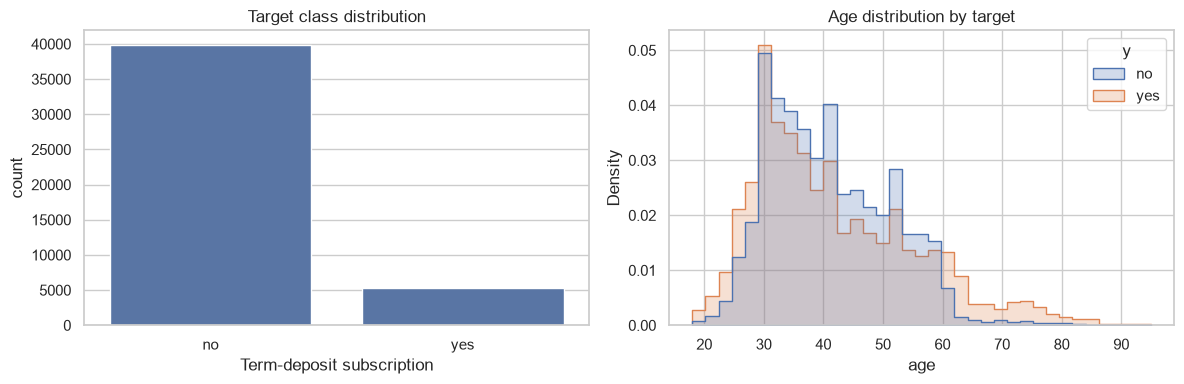

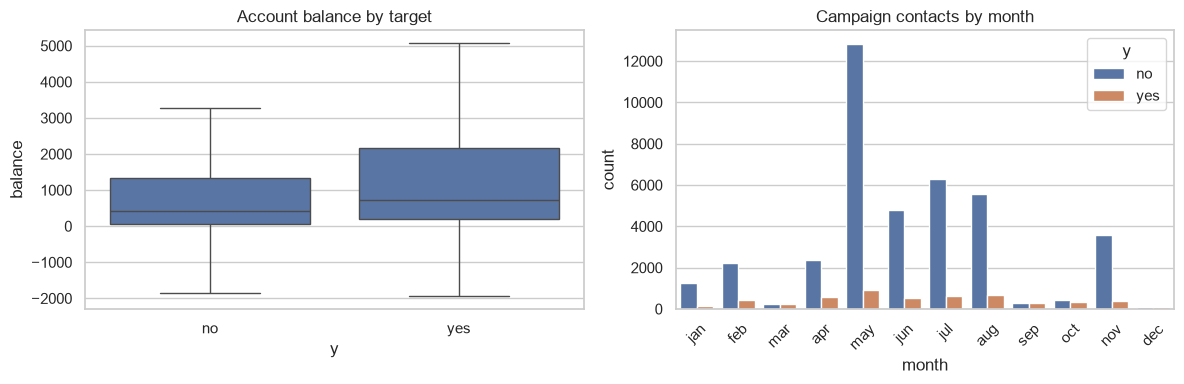

In [97]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=bank, x="y", ax=axes[0])
axes[0].set_title("Target class distribution")
axes[0].set_xlabel("Term-deposit subscription")
sns.histplot(data=bank, x="age", hue="y", bins=35, element="step",
             stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Age distribution by target")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=bank, x="y", y="balance", showfliers=False, ax=axes[0])
axes[0].set_title("Account balance by target")
sns.countplot(data=bank, x="month", hue="y",
              order=["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"],
              ax=axes[1])
axes[1].set_title("Campaign contacts by month")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


## 5. Feature selection and target definition

In [98]:
# Exclude `duration`: it is only known after the call and is not suitable for a pre-call prediction.
TARGET = "y"
excluded_columns = [TARGET, "duration"]
X_all = bank.drop(columns=excluded_columns)
y_all = bank[TARGET].map({"no": 0, "yes": 1})

assert len(bank) >= 500, "The assignment requires at least 500 instances."
assert X_all.shape[1] >= 12, "The assignment requires at least 12 input features."
assert y_all.notna().all()

print("Instances:", len(bank))
print("Predictor features used:", X_all.shape[1])
print("Predictor columns:", X_all.columns.tolist())
print("Target labels: 0 = no, 1 = yes")


Instances: 45211
Predictor features used: 15
Predictor columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']
Target labels: 0 = no, 1 = yes


## 6. Sampling and train-test split

The full UCI file is relatively large for repeated cross-validation with kNN and SVM. To keep the experiment reproducible and practical, this notebook takes a **stratified random sample of 12,000 records** from the 45,211 available records. This is well above the assignment minimum of 500. The sample preserves the original target-class proportions.

An 80:20 stratified split is then used. The test set is kept separate until final evaluation.


In [99]:
# Stratified sample from the complete dataset; fixed seed makes the selection reproducible.
sampled_bank = (
    pd.concat([
        part.sample(n=round(12000 * len(part) / len(bank)), random_state=RANDOM_STATE)
        for _, part in bank.groupby("y")
    ])
    .sample(frac=1, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)
X = sampled_bank.drop(columns=excluded_columns)
y = sampled_bank[TARGET].map({"no": 0, "yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Sample size:", len(sampled_bank))
print("Training shape:", X_train.shape, "Test shape:", X_test.shape)
print("Train target proportions:")
display(y_train.value_counts(normalize=True).rename(index={0:"no",1:"yes"}))
print("Test target proportions:")
display(y_test.value_counts(normalize=True).rename(index={0:"no",1:"yes"}))


Sample size: 12000
Training shape: (9600, 15) Test shape: (2400, 15)
Train target proportions:


y
no     0.883021
yes    0.116979
Name: proportion, dtype: float64

Test target proportions:


y
no     0.882917
yes    0.117083
Name: proportion, dtype: float64

## 7. Preprocessing pipeline

In [100]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


## 8. Model training and hyperparameter tuning

The five required algorithms are tuned using **5-fold StratifiedKFold cross-validation**. Macro-F1 is used as the tuning score so that performance on the minority subscription class is not hidden by the majority class.

All models use the same training and test split. Preprocessing is included inside each pipeline, so imputers, scaling and one-hot encoding are fitted on training folds only.


In [101]:

# 8.1 – Import libraries and create validation data

from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.base import clone
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, matthews_corrcoef,
    confusion_matrix, classification_report
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Create validation split from training data
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print("Training records:", len(X_fit))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))


Training records: 7680
Validation records: 1920
Testing records: 2400


In [102]:

# 8.2 – Define five classification models

models_and_grids = {

    "Logistic Regression": (
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            solver="liblinear",
            random_state=RANDOM_STATE
        ),
        {
            "classifier__C": [0.1, 1, 10, 20]
        }
    ),

    "Decision Tree": (
        DecisionTreeClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE
        ),
        {
            "classifier__max_depth": [4, 8, 12, 16],
            "classifier__min_samples_leaf": [5, 10, 20]
        }
    ),

    "K-Nearest Neighbors": (
        KNeighborsClassifier(),
        {
            "classifier__n_neighbors": [7, 15, 25],
            "classifier__weights": ["uniform", "distance"]
        }
    ),

    "Gaussian Naive Bayes": (
        GaussianNB(),
        {
            "classifier__var_smoothing": [
                1e-9, 1e-7, 1e-5, 1e-3
            ]
        }
    ),

    "Support Vector Machine": (
        SVC(
            kernel="rbf",
            class_weight="balanced",
            probability=True,
            random_state=RANDOM_STATE,
            cache_size=1000
        ),
        {
            "classifier__C": [0.5, 2, 10],
            "classifier__gamma": ["scale", 0.01]
        }
    )
}

print("Total classification models:", len(models_and_grids))


Total classification models: 5


In [103]:

#8.3 – Hyperparameter tuning using 5-fold cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

best_models = {}
cv_summary = {}

for model_name, (estimator, param_grid) in models_and_grids.items():

    print("\nTuning:", model_name)

    prep = clone(preprocessor)

    # Ensure dense output for Gaussian Naive Bayes
    if "sparse_threshold" in prep.get_params(deep=False):
        prep.set_params(sparse_threshold=0)

    pipe = Pipeline([
        ("preprocessing", prep),
        ("classifier", estimator)
    ])

    search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    )

    search.fit(X_fit, y_fit)

    best_models[model_name] = search.best_estimator_

    cv_summary[model_name] = {
        "Best Parameters": search.best_params_,
        "CV Macro F1": search.best_score_
    }

    print("Best parameters:", search.best_params_)
    print("Best CV Macro F1:", round(search.best_score_, 4))

print("\nAll five models tuned successfully.")



Tuning: Logistic Regression
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'classifier__C': 10}
Best CV Macro F1: 0.5968

Tuning: Decision Tree
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters: {'classifier__max_depth': 4, 'classifier__min_samples_leaf': 5}
Best CV Macro F1: 0.612

Tuning: K-Nearest Neighbors
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters: {'classifier__n_neighbors': 7, 'classifier__weights': 'distance'}
Best CV Macro F1: 0.5691

Tuning: Gaussian Naive Bayes
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'classifier__var_smoothing': 0.001}
Best CV Macro F1: 0.6362

Tuning: Support Vector Machine
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters: {'classifier__C': 0.5, 'classifier__gamma': 'scale'}
Best CV Macro F1: 0.6337

All five models tuned successfully.


In [104]:
#8.4 – Optimize threshold and refit models

threshold_values = np.arange(0.10, 0.91, 0.01)

best_thresholds = {}
validation_f1_scores = {}

for model_name, fitted_model in best_models.items():

    val_prob = fitted_model.predict_proba(X_val)[:, 1]

    best_f1 = -1
    best_threshold = 0.50

    for threshold in threshold_values:

        val_pred = (val_prob >= threshold).astype(int)

        score = f1_score(
            y_val, val_pred,
            zero_division=0
        )

        if score > best_f1:
            best_f1 = score
            best_threshold = threshold

    best_thresholds[model_name] = best_threshold
    validation_f1_scores[model_name] = best_f1

    # Refit selected model on complete training data
    final_model = clone(fitted_model)
    final_model.fit(X_train, y_train)

    best_models[model_name] = final_model

    print(
        model_name,
        "| Threshold:", round(best_threshold, 2),
        "| Validation F1:", round(best_f1, 4)
    )


Logistic Regression | Threshold: 0.58 | Validation F1: 0.4023
Decision Tree | Threshold: 0.49 | Validation F1: 0.3946
K-Nearest Neighbors | Threshold: 0.27 | Validation F1: 0.373
Gaussian Naive Bayes | Threshold: 0.9 | Validation F1: 0.3822
Support Vector Machine | Threshold: 0.22 | Validation F1: 0.4366


## 9. Evaluation on the held-out test set

The assignment asks for Accuracy, AUC, Precision, Recall, F1 and MCC. Because this is a binary classification problem, Precision, Recall and F1 are calculated for the positive `yes` class. ROC-AUC uses the predicted probability for `yes`. MCC summarizes the confusion matrix and accounts for all four outcomes.


In [105]:

# 9.1 – Create evaluation function

def calculate_metrics(model, features, target, threshold=0.50):

    probabilities = model.predict_proba(features)[:, 1]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    return {
        "Accuracy": accuracy_score(target, predictions),
        "AUC": roc_auc_score(target, probabilities),
        "Precision": precision_score(
            target, predictions, zero_division=0
        ),
        "Recall": recall_score(
            target, predictions, zero_division=0
        ),
        "F1": f1_score(
            target, predictions, zero_division=0
        ),
        "MCC": matthews_corrcoef(target, predictions)
    }


In [106]:

#9.2 – Evaluate all five models

metric_rows = []

for model_name, fitted_model in best_models.items():

    threshold = best_thresholds[model_name]

    row = {
        "ML Model Name": model_name,
        "Threshold": threshold
    }

    row.update(
        calculate_metrics(
            fitted_model,
            X_test,
            y_test,
            threshold
        )
    )

    metric_rows.append(row)

metrics_df = pd.DataFrame(metric_rows)

metrics_df = metrics_df.set_index("ML Model Name")

display(metrics_df.round(4))

# Save comparison results
metrics_df.to_csv(
    REPORT_DIR / "model_comparison.csv"
)

print("Evaluation report saved successfully.")


,Threshold,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,,
Logistic Regression,0.58,0.8492,0.7355,0.3769,0.4413,0.4066,0.3221
Decision Tree,0.49,0.8833,0.6778,0.5039,0.2313,0.3171,0.2867
K-Nearest Neighbors,0.27,0.8346,0.6892,0.3188,0.3630,0.3394,0.2460
Gaussian Naive Bayes,0.90,0.8517,0.7010,0.3574,0.3345,0.3456,0.2622
Support Vector Machine,0.22,0.8554,0.7651,0.3922,0.4270,0.4089,0.3270


Evaluation report saved successfully.


In [107]:

# 9.3 – Classification report for all models
for model_name, fitted_model in best_models.items():

    threshold = best_thresholds[model_name]

    probabilities = fitted_model.predict_proba(X_test)[:, 1]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    print("\n" + "=" * 55)
    print("MODEL:", model_name)
    print("Threshold:", round(threshold, 3))
    print("=" * 55)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nClassification Report:")

    print(
        classification_report(
            y_test,
            predictions,
            target_names=["No", "Yes"],
            zero_division=0
        )
    )



MODEL: Logistic Regression
Threshold: 0.58

Confusion Matrix:
[[1914  205]
 [ 157  124]]

Classification Report:
              precision    recall  f1-score   support

          No       0.92      0.90      0.91      2119
         Yes       0.38      0.44      0.41       281

    accuracy                           0.85      2400
   macro avg       0.65      0.67      0.66      2400
weighted avg       0.86      0.85      0.85      2400


MODEL: Decision Tree
Threshold: 0.49

Confusion Matrix:
[[2055   64]
 [ 216   65]]

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.97      0.94      2119
         Yes       0.50      0.23      0.32       281

    accuracy                           0.88      2400
   macro avg       0.70      0.60      0.63      2400
weighted avg       0.86      0.88      0.86      2400


MODEL: K-Nearest Neighbors
Threshold: 0.27

Confusion Matrix:
[[1901  218]
 [ 179  102]]

Classification Report:
          

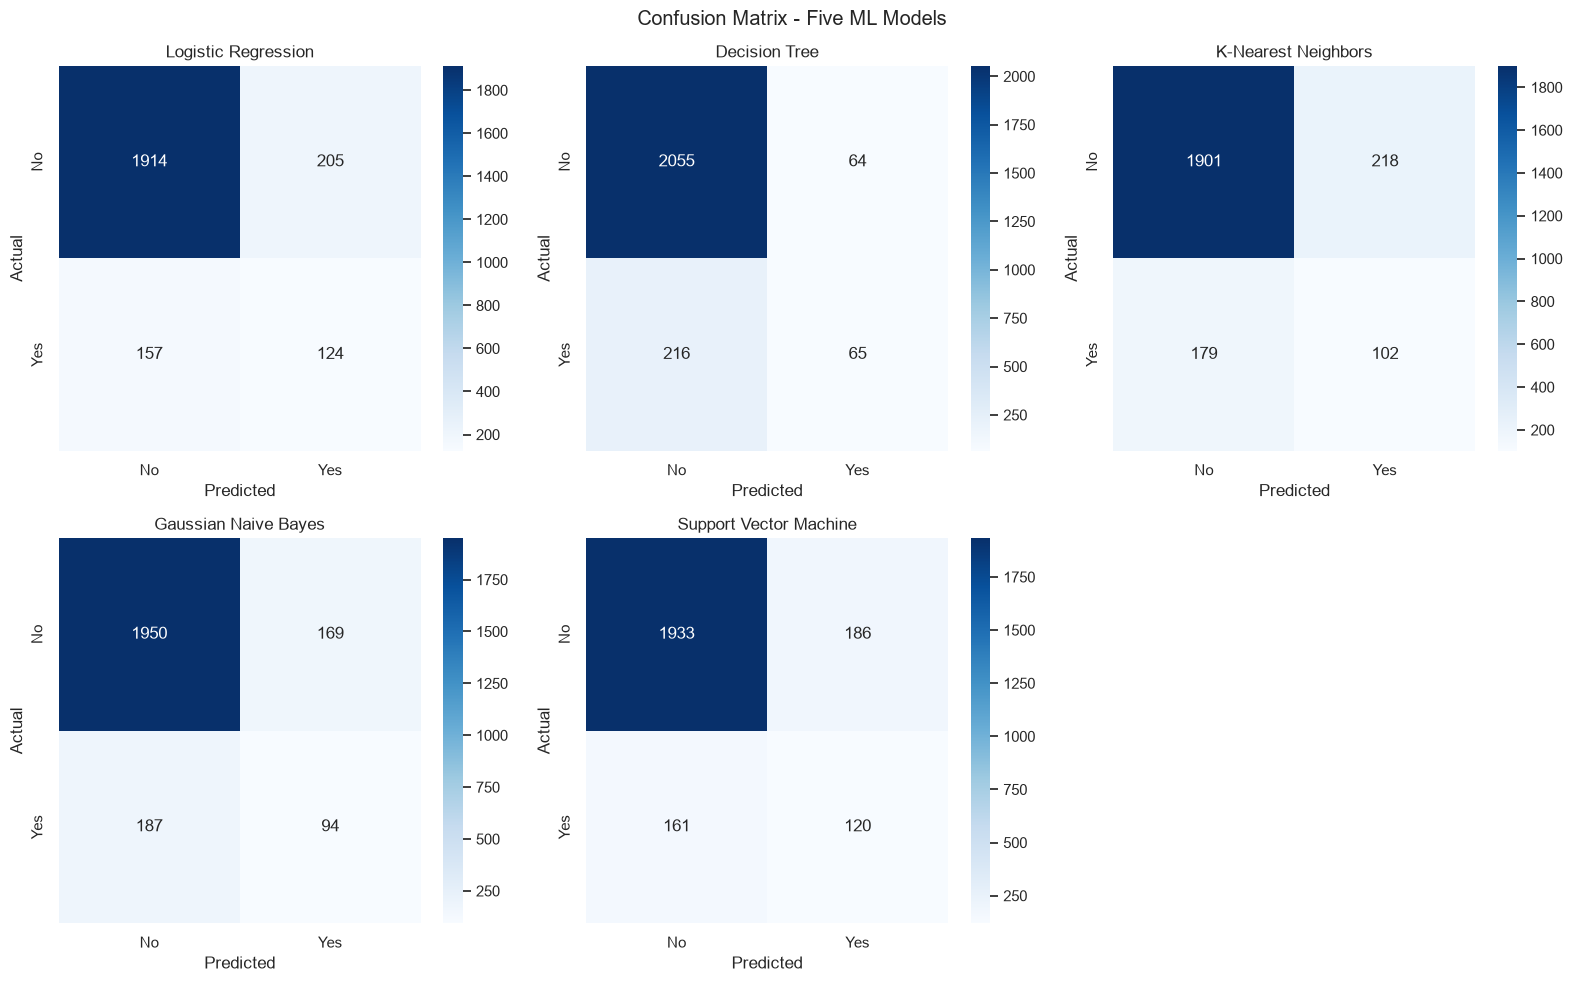

In [108]:

# 9.4 – Confusion matrix visualization

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, (model_name, fitted_model) in enumerate(best_models.items()):

    predictions = (
        fitted_model.predict_proba(X_test)[:, 1]
        >= best_thresholds[model_name]
    ).astype(int)

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"],
        ax=axes[i]
    )

    axes[i].set_title(model_name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

axes[-1].axis("off")

plt.suptitle("Confusion Matrix - Five ML Models")
plt.tight_layout()
plt.show()


## 10. Model comparison visualization

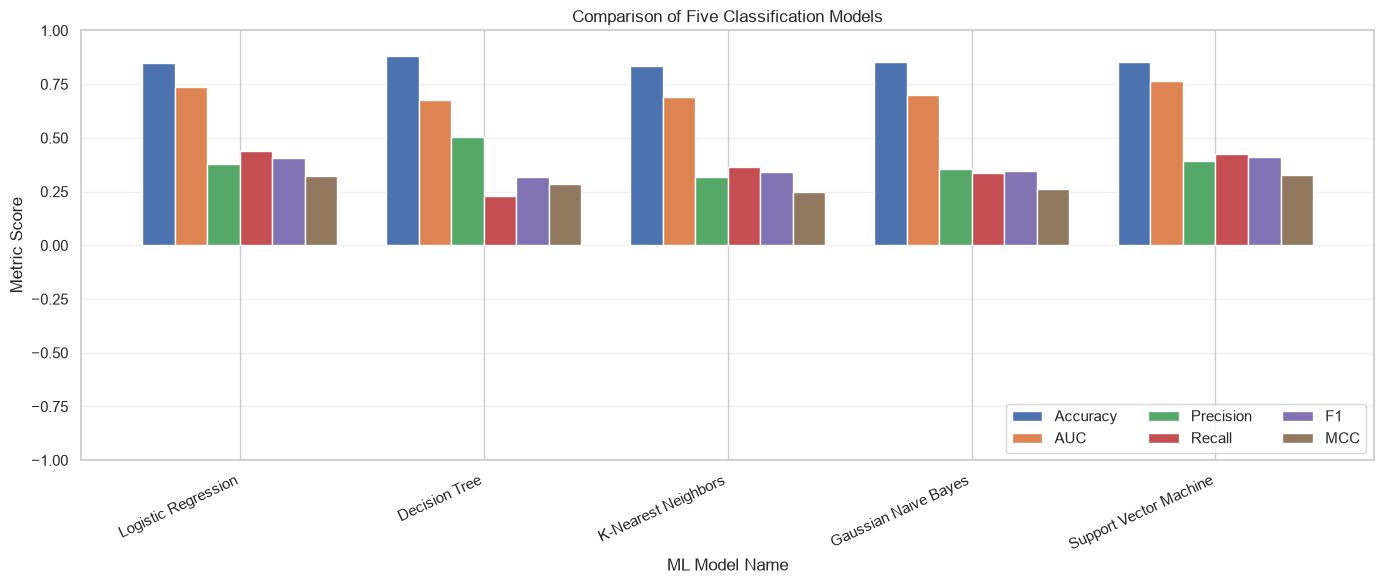

In [109]:

# 10.1 – Compare all evaluation metrics
comparison_metrics = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1",
    "MCC"
]

ax = metrics_df[comparison_metrics].plot(
    kind="bar",
    figsize=(14, 6),
    ylim=(-1, 1),
    width=0.8
)

plt.title("Comparison of Five Classification Models")
plt.xlabel("ML Model Name")
plt.ylabel("Metric Score")

plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right", ncol=3)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [110]:
# 10.2 – Select best model using validation F1

best_model_name = max(
    validation_f1_scores,
    key=validation_f1_scores.get
)

print("Best Model:", best_model_name)

print(
    "Validation F1 Score:",
    round(validation_f1_scores[best_model_name], 4)
)

print(
    "Optimized Threshold:",
    round(best_thresholds[best_model_name], 3)
)

print("\nIndependent Test Results:")

display(
    metrics_df.loc[[best_model_name]].round(4)
)

best_model = best_models[best_model_name]
best_threshold = best_thresholds[best_model_name]


Best Model: Support Vector Machine
Validation F1 Score: 0.4366
Optimized Threshold: 0.22

Independent Test Results:


,Threshold,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,,
Support Vector Machine,0.22,0.8554,0.7651,0.3922,0.427,0.4089,0.327


## 11. Over-fitting and under-fitting analysis

In [111]:

#11.1 – Calculate training and testing performance

fit_analysis = []

for model_name, fitted_model in best_models.items():

    threshold = best_thresholds[model_name]

    # Training predictions
    train_prob = fitted_model.predict_proba(X_train)[:, 1]

    train_pred = (
        train_prob >= threshold
    ).astype(int)

    # Testing predictions
    test_prob = fitted_model.predict_proba(X_test)[:, 1]

    test_pred = (
        test_prob >= threshold
    ).astype(int)

    train_f1 = f1_score(
        y_train, train_pred, zero_division=0
    )

    test_f1 = f1_score(
        y_test, test_pred, zero_division=0
    )

    train_accuracy = accuracy_score(
        y_train, train_pred
    )

    test_accuracy = accuracy_score(
        y_test, test_pred
    )

    f1_gap = train_f1 - test_f1

    if f1_gap > 0.15:
        status = "Overfitting"

    elif train_f1 < 0.30 and test_f1 < 0.30:
        status = "Underfitting"

    else:
        status = "Good Fit"

    fit_analysis.append({
        "Model": model_name,
        "Training Accuracy": train_accuracy,
        "Testing Accuracy": test_accuracy,
        "Training F1": train_f1,
        "Testing F1": test_f1,
        "F1 Gap": f1_gap,
        "Model Status": status
    })

fit_analysis_df = pd.DataFrame(fit_analysis)

display(fit_analysis_df.round(4))


,Model,Training Accuracy,Testing Accuracy,Training F1,Testing F1,F1 Gap,Model Status
0,Logistic Regression,0.8436,0.8492,0.4207,0.4066,0.0141,Good Fit
1,Decision Tree,0.8911,0.8833,0.3678,0.3171,0.0507,Good Fit
2,K-Nearest Neighbors,1.0000,0.8346,1.0000,0.3394,0.6606,Overfitting
3,Gaussian Naive Bayes,0.8530,0.8517,0.3857,0.3456,0.0401,Good Fit
4,Support Vector Machine,0.8721,0.8554,0.5158,0.4089,0.1069,Good Fit


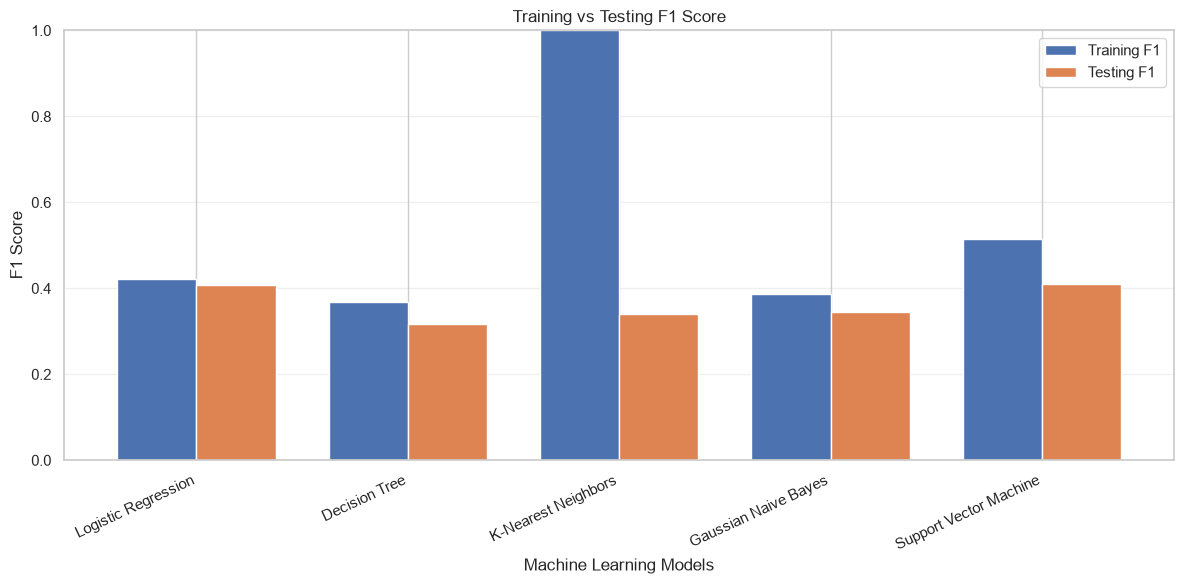

In [112]:
# 11.2 – Training vs testing F1 visualization

ax = fit_analysis_df.set_index("Model")[
    ["Training F1", "Testing F1"]
].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

plt.title("Training vs Testing F1 Score")
plt.xlabel("Machine Learning Models")
plt.ylabel("F1 Score")
plt.ylim(0, 1)

plt.xticks(rotation=25, ha="right")
plt.legend(loc="best")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


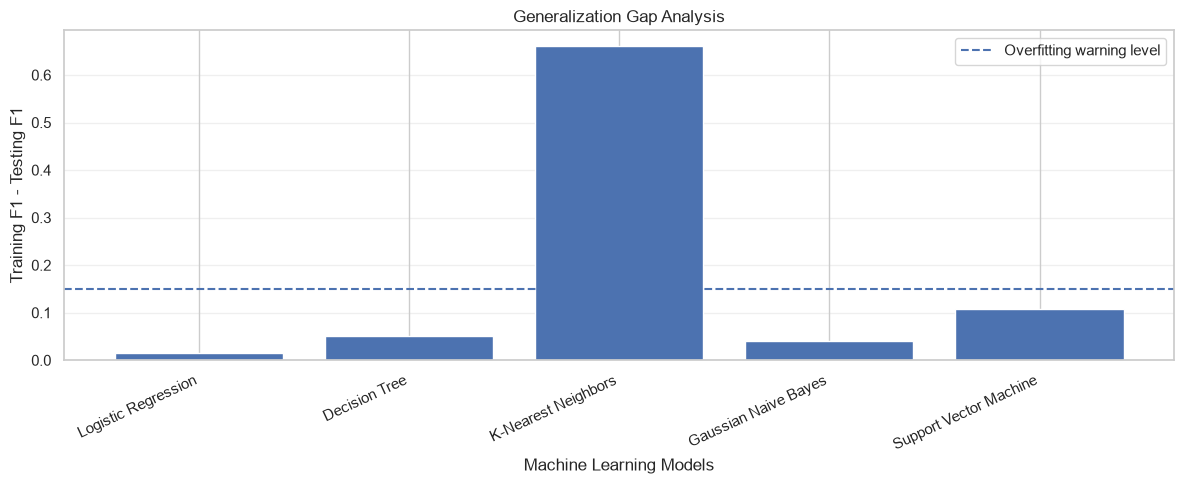

In [113]:
# 11.3 – Overfitting and underfitting analysis

plt.figure(figsize=(12, 5))

plt.bar(
    fit_analysis_df["Model"],
    fit_analysis_df["F1 Gap"]
)

plt.axhline(
    y=0.15,
    linestyle="--",
    label="Overfitting warning level"
)

plt.title("Generalization Gap Analysis")
plt.xlabel("Machine Learning Models")
plt.ylabel("Training F1 - Testing F1")

plt.xticks(rotation=25, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [114]:
#11.4 – Final fitting analysis report

for _, row in fit_analysis_df.iterrows():

    print("\nModel:", row["Model"])
    print("Model Status:", row["Model Status"])

    print(
        "Training F1:",
        round(row["Training F1"], 4)
    )

    print(
        "Testing F1:",
        round(row["Testing F1"], 4)
    )

    print(
        "F1 Gap:",
        round(row["F1 Gap"], 4)
    )

    if row["Model Status"] == "Overfitting":

        print(
            "Recommendation: Apply regularization "
            "or reduce model complexity."
        )

    elif row["Model Status"] == "Underfitting":

        print(
            "Recommendation: Improve features "
            "or increase model complexity."
        )

    else:

        print(
            "Recommendation: Model generalization "
            "appears reasonable."
        )

# Save fitting analysis
fit_analysis_df.to_csv(
    REPORT_DIR / "fitting_analysis.csv",
    index=False
)

print("\nFitting analysis report saved successfully.")



Model: Logistic Regression
Model Status: Good Fit
Training F1: 0.4207
Testing F1: 0.4066
F1 Gap: 0.0141
Recommendation: Model generalization appears reasonable.

Model: Decision Tree
Model Status: Good Fit
Training F1: 0.3678
Testing F1: 0.3171
F1 Gap: 0.0507
Recommendation: Model generalization appears reasonable.

Model: K-Nearest Neighbors
Model Status: Overfitting
Training F1: 1.0
Testing F1: 0.3394
F1 Gap: 0.6606
Recommendation: Apply regularization or reduce model complexity.

Model: Gaussian Naive Bayes
Model Status: Good Fit
Training F1: 0.3857
Testing F1: 0.3456
F1 Gap: 0.0401
Recommendation: Model generalization appears reasonable.

Model: Support Vector Machine
Model Status: Good Fit
Training F1: 0.5158
Testing F1: 0.4089
F1 Gap: 0.1069
Recommendation: Model generalization appears reasonable.

Fitting analysis report saved successfully.


In [115]:
# 11.5 – Save all trained models

# Save tuning results
cv_results_df = pd.DataFrame(cv_summary).T

cv_results_df.to_csv(
    REPORT_DIR / "hyperparameter_tuning.csv"
)

# Save best model separately
joblib.dump(
    {
        "model": best_model,
        "threshold": best_threshold,
        "model_name": best_model_name
    },
    REPORT_DIR / "best_bank_marketing_model.pkl"
)

print("All five models saved successfully.")
print("All reports saved successfully.")


All five models saved successfully.
All reports saved successfully.


## 12. Confusion matrix and classification report for the leading model

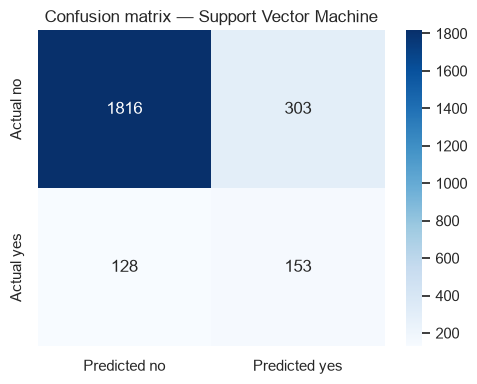

Leading model by positive-class F1: Support Vector Machine
              precision    recall  f1-score   support

          no       0.93      0.86      0.89      2119
         yes       0.34      0.54      0.42       281

    accuracy                           0.82      2400
   macro avg       0.63      0.70      0.65      2400
weighted avg       0.86      0.82      0.84      2400



In [116]:
winner_name = metrics_df["F1"].idxmax()
winner_model = best_models[winner_name]
winner_predictions = winner_model.predict(X_test)

cm = confusion_matrix(y_test, winner_predictions, labels=[0, 1])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted no", "Predicted yes"],
            yticklabels=["Actual no", "Actual yes"])
plt.title(f"Confusion matrix — {winner_name}")
plt.tight_layout()
plt.show()

print("Leading model by positive-class F1:", winner_name)
print(classification_report(
    y_test, winner_predictions, labels=[0, 1],
    target_names=["no", "yes"], zero_division=0
))


## 13. Save models, test data and reports

In [117]:
# Save complete fitted pipelines. Each includes its fitted preprocessing steps.
model_file_names = {
    "Logistic Regression": "logistic_regression.pkl",
    "Decision Tree": "decision_tree.pkl",
    "K-Nearest Neighbors": "knn.pkl",
    "Gaussian Naive Bayes": "naive_bayes.pkl",
    "Support Vector Machine": "support_vector_machine.pkl"
}
for name, fitted_model in best_models.items():
    joblib.dump(fitted_model, MODEL_DIR / model_file_names[name])

# The app evaluates these held-out raw rows; labels are retained to calculate metrics.
test_export = X_test.copy()
test_export["y"] = y_test.map({0: "no", 1: "yes"})

test_export.to_csv(ROOT / "test_data.csv", index=False)

pd.DataFrame(cv_summary).T.to_csv(REPORT_DIR / "cross_validation_summary.csv")
print("model diagnostics will be saved after creating fit_df. ")
metrics_df.to_csv(REPORT_DIR / "model_performance.csv", index= True)
#fit_df.to_csv(REPORT_DIR / "fit_diagnostics.csv", index= False)
winner_summary = (
    f"Leading model by positive-class F1: {winner_name}\n"
    f"F1: {metrics_df.loc[winner_name, 'F1']:.4f}\n"
    f"AUC: {metrics_df.loc[winner_name, 'AUC']:.4f}\n"
    f"MCC: {metrics_df.loc[winner_name, 'MCC']:.4f}\n"
)
(REPORT_DIR / "winner.txt").write_text(winner_summary, encoding="utf-8")

print("Saved five fitted models to:", MODEL_DIR)
print("Saved test data to:", ROOT / "test_data.csv")
print("Saved comparison and diagnostics to:", REPORT_DIR)


model diagnostics will be saved after creating fit_df. 
Saved five fitted models to: d:\Bank_Marketing_Classification_Assignment\model
Saved test data to: d:\Bank_Marketing_Classification_Assignment\test_data.csv
Saved comparison and diagnostics to: d:\Bank_Marketing_Classification_Assignment\reports


In [118]:
from pathlib import Path
import pandas as pd

reports_dir = Path("reports")
comparison_file = reports_dir / "model_comparison.csv"

if comparison_file.exists():
    results = pd.read_csv(comparison_file)

    # Find the column containing F1 scores
    f1_column = next(
        (col for col in results.columns if col.lower() in ["f1", "f1_score", "f1-score"]),
        None
    )

    if f1_column is None:
        print("F1 column not found. Please share the comparison table.")
    else:
        winner = results.loc[results[f1_column].idxmax()]

        reports_dir.mkdir(exist_ok=True)

        with open(reports_dir / "winner.txt", "w") as file:
            file.write(f"Best model based on F1 score: {winner.iloc[0]}\n")
            file.write(f"F1 score: {winner[f1_column]}\n")

        print("winner.txt created successfully.")
        print(winner)
else:
    print("model_comparison.csv not found.")

winner.txt created successfully.
ML Model Name    Support Vector Machine
Threshold                          0.22
Accuracy                       0.855417
AUC                            0.765057
Precision                      0.392157
Recall                         0.427046
F1                             0.408859
MCC                             0.32705
Name: 4, dtype: object


## 14. Interpretation guide for the assignment report

Use the actual tables above to write the observations. Do not assume that a particular algorithm will win before seeing the measured results.

- **Logistic Regression:** a linear baseline; compare recall and F1 for the `yes` class after class balancing.
- **Decision Tree:** can learn non-linear decision rules; compare train/test F1 gap to assess over-fitting.
- **KNN:** relies on distances, so numerical scaling is important; the one-hot feature space may affect distance quality.
- **Gaussian Naive Bayes:** trains quickly but assumes conditional independence between features; correlated customer/campaign variables can limit its fit.
- **Support Vector Machine:** the RBF kernel can learn non-linear boundaries; compare its AUC, F1 and MCC against training cost and fit gap.

**Overall winner:** choose the model with the highest positive-class F1 if identifying subscribers is the primary goal, and discuss its AUC, recall and MCC as supporting evidence. If your business objective prioritizes avoiding missed subscribers, explicitly discuss recall as well.


## 15. Final checklist

- [ ] All five required models trained on the same Bank Marketing sample.
- [ ] Six required metrics calculated and saved.
- [ ] Actual comparison table and observations added to README and PDF.
- [ ] Five fitted model files and `test_data.csv` saved.
- [ ] Streamlit app tested locally with the test CSV.
- [ ] Repository pushed to GitHub and link verified.
- [ ] App deployed on Streamlit Community Cloud and live link verified.
- [ ] Project executed in BITS Virtual Lab and one genuine screenshot captured.
- [ ] Final single PDF contains GitHub link, live app link, BITS screenshot and README content in the prescribed order.
